In [1]:
!pip install pandas numpy matplotlib seaborn requests

In [2]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Retrieving the following datasets:
# German electricity generation by source, in MW
# German day-ahead electricity prices, in EUR/MWh

BASE_URL = "https://api.energy-charts.info/v2"

START_DATE = "2025-11-01"
END_DATE = "2026-11-05"

# Get electricity generation
generation_response = requests.get(
    f"{BASE_URL}/public_power",
    params={
        "country": "de",
        "start": START_DATE,
        "end": END_DATE
    },
    timeout=60
)

generation_response.raise_for_status()
generation_data = generation_response.json()

# Get day-ahead electricity prices
price_response = requests.get(
    f"{BASE_URL}/price",
    params={
        "bzn": "DE-LU",
        "start": START_DATE,
        "end": END_DATE
    },
    timeout=60
)

price_response.raise_for_status()
price_data = price_response.json()

print("Generation records:", len(generation_data["data"]))
print("Price records:", len(price_data["data"]))

Generation records: 35520
Price records: 35520


In [4]:
def extract_timeseries(payload):
    """Convert Energy-Charts v2 response into a DataFrame."""

    records = []

    for item in payload["data"]:
        record = {"timestamp": item["timestamp"]}
        record.update(item["values"])
        records.append(record)

    df = pd.DataFrame(records)

    df["timestamp"] = pd.to_datetime(
        df["timestamp"], utc=True
    ).dt.tz_convert("Europe/Berlin")

    return df


# Prepare generation data
generation = extract_timeseries(generation_data)

# Prepare price data
prices = extract_timeseries(price_data)

# Identify generation columns
solar_col = next(
    col for col in generation.columns
    if col.lower() == "solar"
)

wind_cols = [
    col for col in generation.columns
    if col.lower().startswith("wind")
]

# Calculate combined renewable generation
generation["solar_mw"] = generation[solar_col]
generation["wind_mw"] = generation[wind_cols].sum(axis=1)

generation["wind_solar_mw"] = (
    generation["solar_mw"] + generation["wind_mw"]
)

# Identify the price column
price_cols = [
    col for col in prices.columns
    if col != "timestamp"
]

price_col = price_cols[0]

prices["price_eur_mwh"] = prices[price_col]

# Aggregate both datasets to hourly averages
generation_hourly = (
    generation.set_index("timestamp")
    [["solar_mw", "wind_mw", "wind_solar_mw"]]
    .resample("1h").mean()
)

prices_hourly = (
    prices.set_index("timestamp")
    [["price_eur_mwh"]]
    .resample("1h").mean()
)

# Combine datasets
df = generation_hourly.join(prices_hourly, how="inner")

# Remove missing observations
df = df.dropna()

print(df.head())
print("\nDataset shape:", df.shape)

                           solar_mw    wind_mw  wind_solar_mw  price_eur_mwh
timestamp                                                                   
2025-11-01 00:00:00+01:00     0.000  24416.925      24416.925        54.7075
2025-11-01 01:00:00+01:00     0.000  23944.800      23944.800        38.1150
2025-11-01 02:00:00+01:00     0.000  22869.050      22869.050        28.2725
2025-11-01 03:00:00+01:00     0.000  22492.675      22492.675        29.9575
2025-11-01 04:00:00+01:00     2.725  23415.350      23418.075        19.9025

Dataset shape: (8880, 4)


In [5]:
# Data Exploration

print(df.info())

print("\nDescriptive statistics:")
display(df.describe().round(2))

print("\nMissing values:")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8880 entries, 2025-11-01 00:00:00+01:00 to 2026-11-05 23:00:00+01:00
Freq: h
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   solar_mw       8880 non-null   float64
 1   wind_mw        8880 non-null   float64
 2   wind_solar_mw  8880 non-null   float64
 3   price_eur_mwh  8880 non-null   float64
dtypes: float64(4)
memory usage: 346.9 KB
None

Descriptive statistics:


,solar_mw,wind_mw,wind_solar_mw,price_eur_mwh
count,8880.00,8880.00,8880.00,8880.00
mean,9619.73,16065.50,25685.23,113.20
std,14497.72,10727.33,15220.63,67.82
min,0.00,204.38,701.20,-499.00
25%,0.00,6894.87,13185.88,82.29
50%,343.39,14537.38,23495.01,110.00
75%,15525.80,23333.41,36136.18,146.73
max,58055.52,54111.25,68497.00,697.31



Missing values:
solar_mw         0
wind_mw          0
wind_solar_mw    0
price_eur_mwh    0
dtype: int64


Data Visualisation

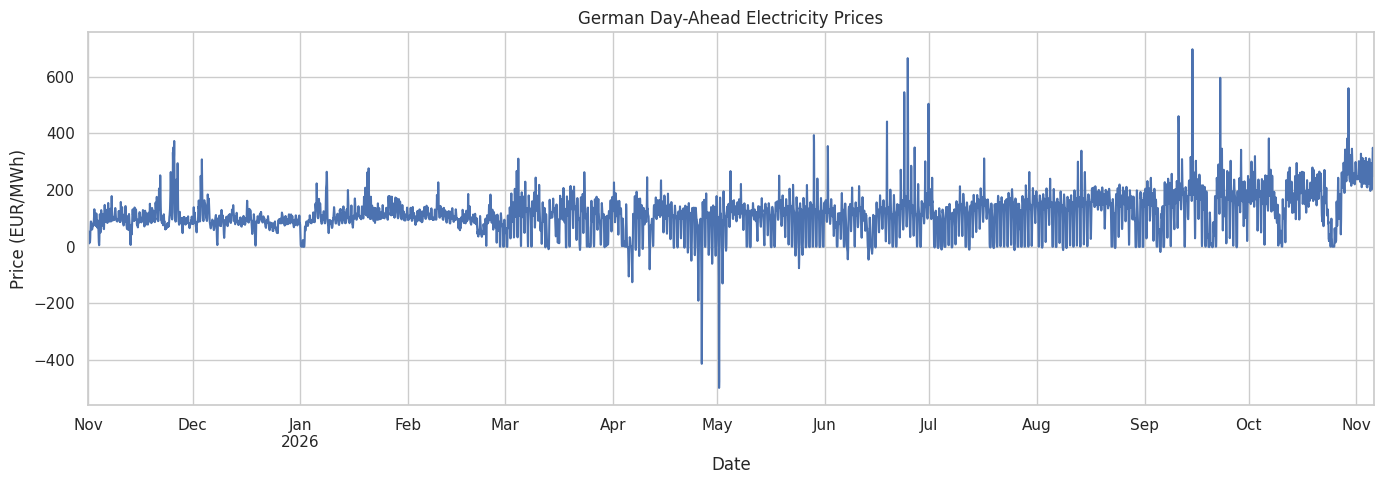

In [6]:
# Electricity price trend

plt.figure(figsize=(14, 5))

df["price_eur_mwh"].plot()

plt.title("German Day-Ahead Electricity Prices")
plt.xlabel("Date")
plt.ylabel("Price (EUR/MWh)")
plt.tight_layout()
plt.show()

<Figure size 1400x500 with 0 Axes>

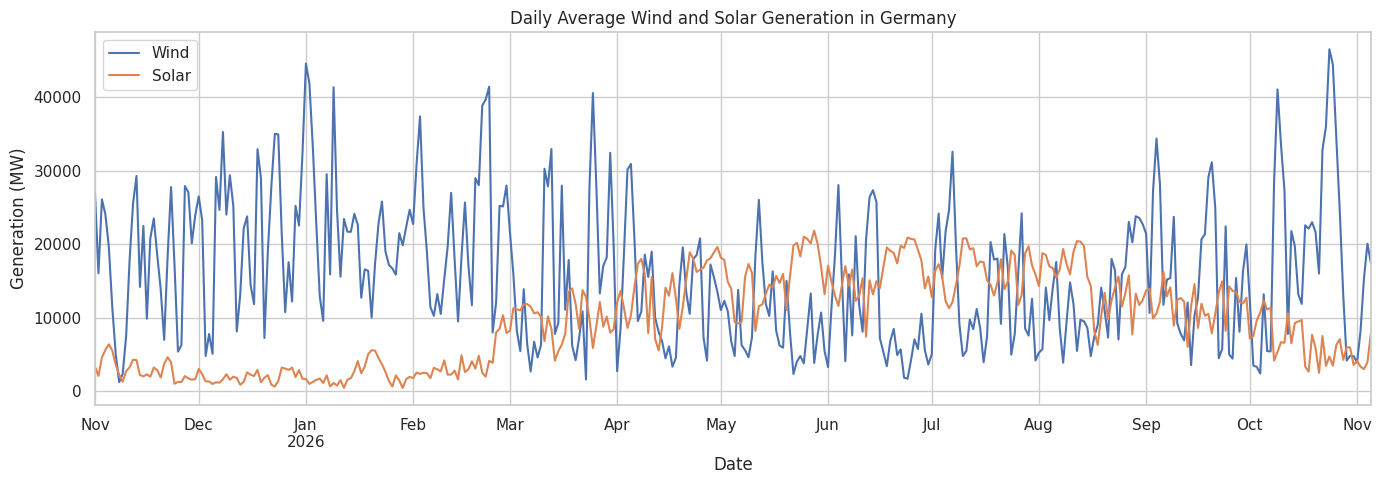

In [7]:
# Wind and solar generation

plt.figure(figsize=(14, 5))

df[["wind_mw", "solar_mw"]].resample("D").mean().plot(
    figsize=(14, 5)
)

plt.title("Daily Average Wind and Solar Generation in Germany")
plt.xlabel("Date")
plt.ylabel("Generation (MW)")
plt.legend(["Wind", "Solar"])
plt.tight_layout()
plt.show()

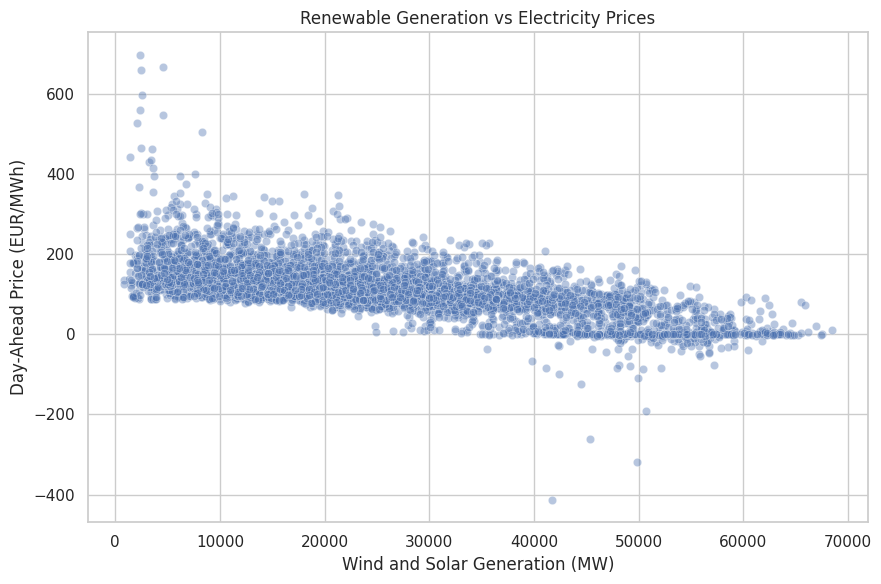

In [8]:
# Renewable generation versus electricity prices

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df.sample(min(5000, len(df)), random_state=42),
    x="wind_solar_mw",
    y="price_eur_mwh",
    alpha=0.4
)

plt.title("Renewable Generation vs Electricity Prices")
plt.xlabel("Wind and Solar Generation (MW)")
plt.ylabel("Day-Ahead Price (EUR/MWh)")
plt.tight_layout()
plt.show()

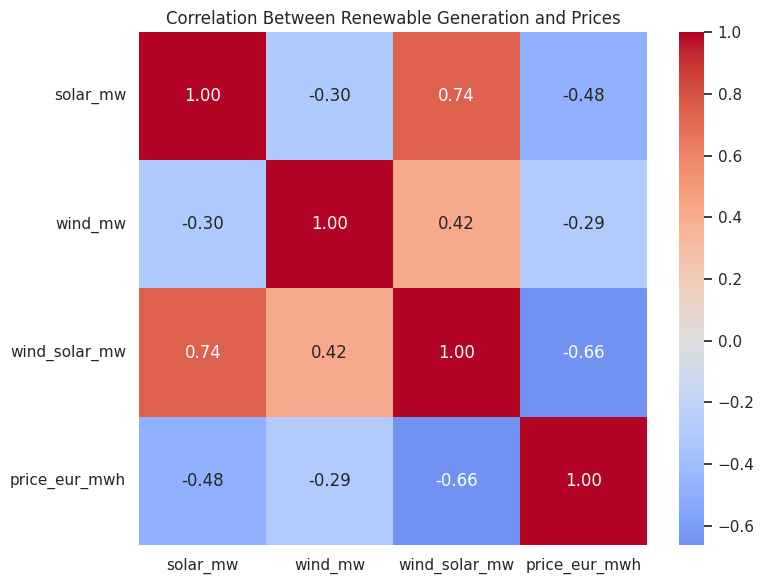

In [9]:
# Correlation heatmap

correlation = df[
    ["solar_mw", "wind_mw",
     "wind_solar_mw", "price_eur_mwh"]
].corr(method="pearson")

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Renewable Generation and Prices")
plt.tight_layout()
plt.show()

Quantitative Analysis

In [10]:
# Calculate Pearson and Spearman correlations

pearson = df[
    ["wind_mw", "solar_mw", "wind_solar_mw", "price_eur_mwh"]
].corr(method="pearson")["price_eur_mwh"]

spearman = df[
    ["wind_mw", "solar_mw", "wind_solar_mw", "price_eur_mwh"]
].corr(method="spearman")["price_eur_mwh"]

print("Pearson correlation with electricity price:")
print(pearson)

print("\nSpearman correlation with electricity price:")
print(spearman)

Pearson correlation with electricity price:
wind_mw         -0.290269
solar_mw        -0.479720
wind_solar_mw   -0.661514
price_eur_mwh    1.000000
Name: price_eur_mwh, dtype: float64

Spearman correlation with electricity price:
wind_mw         -0.320244
solar_mw        -0.322822
wind_solar_mw   -0.684186
price_eur_mwh    1.000000
Name: price_eur_mwh, dtype: float64


In [11]:
# Comapring average prices during periods of low and high renewable generation

df["renewable_group"] = pd.qcut(
    df["wind_solar_mw"],
    q=4,
    labels=["Low", "Moderate-low", "Moderate-high", "High"]
)

price_comparison = (
    df.groupby("renewable_group", observed=True)
    ["price_eur_mwh"]
    .agg(["mean", "median", "count"])
)

display(price_comparison.round(2))

,mean,median,count
renewable_group,,,
Low,162.67,148.34,2220
Moderate-low,134.52,126.00,2220
Moderate-high,108.43,101.54,2220
High,47.20,47.23,2220


Data Export

In [12]:
# Exporting data analysis to CSV file

df.to_csv("germany_energy_market_analysis.csv")

print("Dataset exported successfully!")

Dataset exported successfully!
